# Sample 1 QC - GSM7494324_AML18_DX

In [18]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Reading in the first sample h5ad file
adata = sc.read_h5ad('../raw_adata/GSM7494324_AML18_DX_raw_.h5ad')

In [ ]:
# Filtering out cells with zero counts and adding the total_counts of each barcode to a new column in adata.obs
sc.pp.filter_cells(adata, min_counts=1)
adata.obs['total_counts'] = adata.X.sum(axis=1).A1

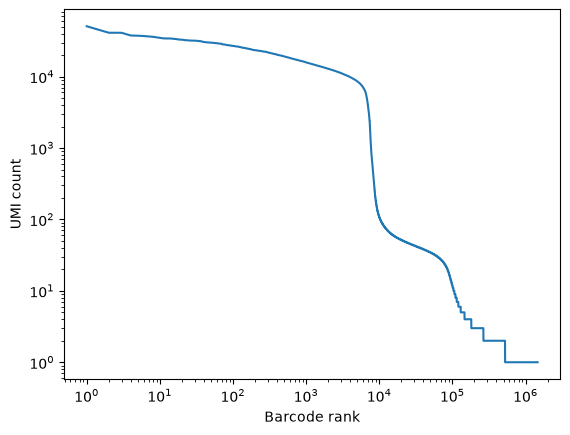

In [ ]:
# Making a kneww plot to rank every barcode from most to least UMIs
counts = np.sort(adata.obs['total_counts'].values)[::-1]
ranks = np.arange(1, len(counts) + 1)

plt.loglog(ranks, counts)
plt.xlabel('Barcode rank'); plt.ylabel('UMI count')
plt.show()

In [24]:
mask = counts >= 100
x, y = np.log10(ranks[mask]), np.log10(counts[mask])

In [25]:
dy = np.gradient(y, x)
dy_smooth = np.convolve(dy, np.ones(50) / 50, mode='same')

In [26]:
inflection = counts[mask][np.argmin(dy_smooth)]

In [28]:
cells = adata[adata.obs['total_counts'] >= inflection].copy()